In [2]:
import pandas as pd
import matplotlib.pyplot as plt 

Na célula abaixo, foi feita a extração do dataFrame e a sua transformação para se adequar na procura dos dados. A transformação feita foi de retirar as colunas que apresentassem valores ausentes

In [3]:
df = pd.read_csv("f1_dnf.csv")
df.iloc[:, :14].head(10)



df.dropna(axis=1,how='any')
df.replace('\\N', pd.NA, inplace=True)

df.dropna(axis=1, inplace=True)



df.head(10)




,resultId,raceId,year,round,grid,positionOrder,driverRef,surname,forename,dob,...,circuitRef,circuitId,name_y,location,country,lat,lng,alt,date,target_finish
0,2460,136,2002,13,11,4,raikkonen,Räikkönen,Kimi,1979-10-17,...,hungaroring,11,McLaren,Budapest,Hungary,47.5789,19.24860,264,2002-08-18,1
1,11565,483,1981,1,23,21,watson,Watson,John,1946-05-04,...,long_beach,43,McLaren,California,USA,33.7651,-118.18900,12,1981-03-15,0
2,18661,772,1958,8,0,26,ruttman,Ruttman,Troy,1930-03-11,...,nurburgring,20,Maserati,Nürburg,Germany,50.3356,6.94750,578,1958-08-03,0
3,25121,1058,2021,8,19,16,mick_schumacher,Schumacher,Mick,1999-03-22,...,red_bull_ring,70,Haas F1 Team,Spielberg,Austria,47.2197,14.76470,678,2021-06-27,0
4,8863,383,1988,12,0,30,modena,Modena,Stefano,1963-05-12,...,monza,14,Euro Brun,Monza,Italy,45.6156,9.28111,162,1988-09-11,0
5,24317,1015,2019,6,5,14,kevin_magnussen,Magnussen,Kevin,1992-10-05,...,monaco,6,Haas F1 Team,Monte-Carlo,Monaco,43.7347,7.42056,7,2019-05-26,0
6,14518,589,1975,14,5,18,mario_andretti,Andretti,Mario,1940-02-28,...,watkins_glen,46,Parnelli,New York State,USA,42.3369,-76.92720,485,1975-10-05,0
7,21966,892,2013,12,16,13,gutierrez,Gutiérrez,Esteban,1991-08-05,...,monza,14,Sauber,Monza,Italy,45.6156,9.28111,162,2013-09-08,1
8,22656,932,2015,7,1,1,hamilton,Hamilton,Lewis,1985-01-07,...,villeneuve,7,Mercedes,Montreal,Canada,45.5000,-73.52280,13,2015-06-07,1
9,18072,746,1960,1,2,6,ireland,Ireland,Innes,1930-06-12,...,galvez,25,Team Lotus,Buenos Aires,Argentina,-34.6943,-58.45930,8,1960-02-07,0


O código filtra apenas as corridas concluídas (target_finish == 1) no ano de 2010 e conta quantas corridas cada piloto terminou.
Em seguida, é criado um gráfico de barras que mostra o desempenho individual dos pilotos, com o eixo X representando os nomes dos pilotos e o eixo Y a quantidade de corridas terminadas.

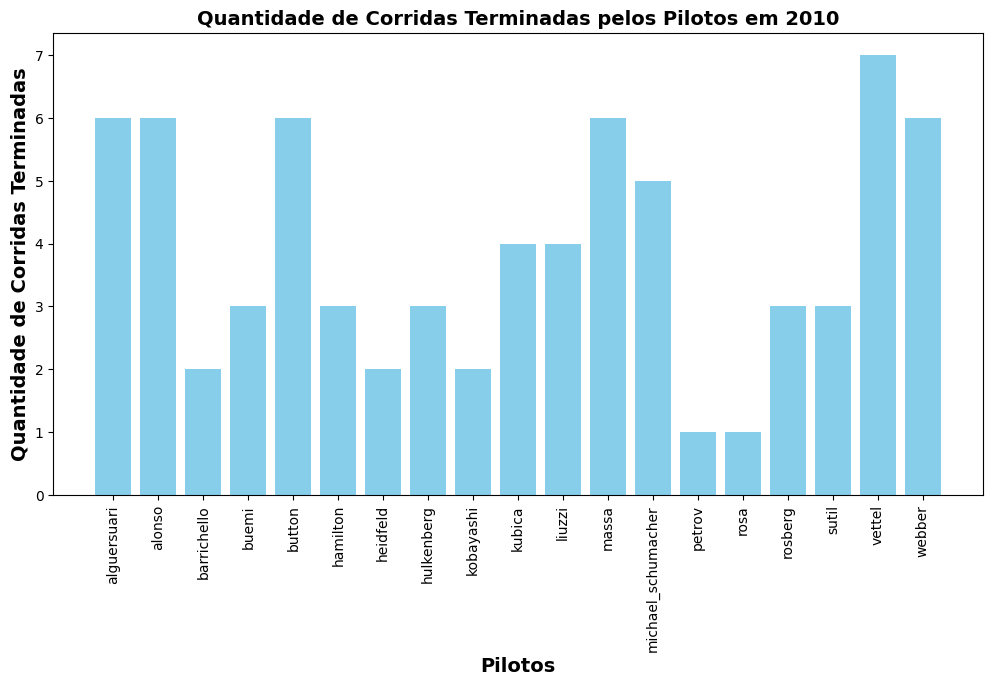

In [8]:
df_pilotos_terminaram = df[ (df['target_finish'] == 1)]


df_2022 = df_pilotos_terminaram[df_pilotos_terminaram['year'] == 2010]


quantidade_por_piloto_2022 = df_2022.groupby('driverRef').size()


plt.figure(figsize=(12, 6))
plt.bar(quantidade_por_piloto_2022.index, quantidade_por_piloto_2022.values, color='skyblue')


plt.title("Quantidade de Corridas Terminadas pelos Pilotos em 2010",fontsize=14, fontweight='bold')
plt.xlabel("Pilotos",fontsize=14, fontweight='bold')
plt.ylabel("Quantidade de Corridas Terminadas",fontsize=14, fontweight='bold')
plt.xticks(rotation=90)  


plt.show()

O gráfico de pizza mostra a proporção de pilotos por nacionalidade no conjunto de dados.
Cada fatia representa um país de origem, e o tamanho indica quantos pilotos daquela nacionalidade competiram na Fórmula 1.

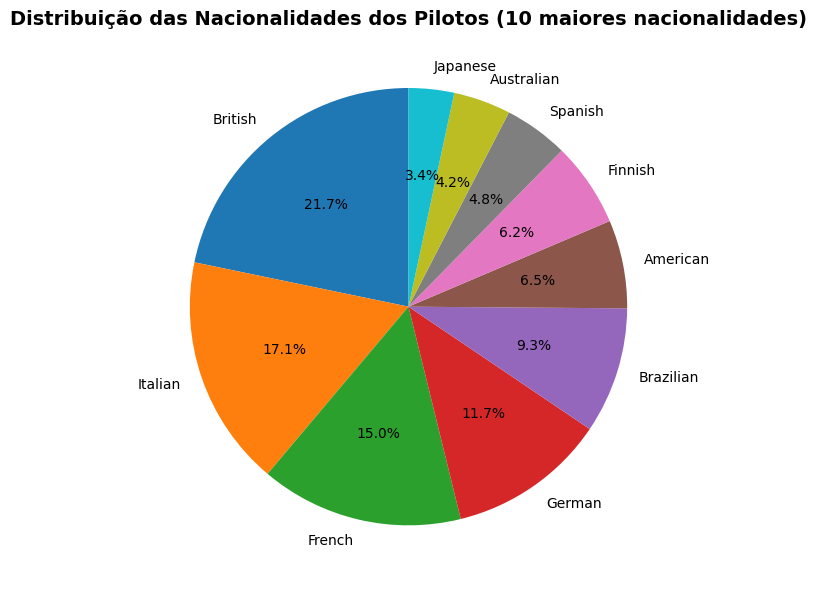

In [10]:
pilotos_por_nacionalidade = df['nationality_x'].value_counts().head(10)  


plt.figure(figsize=(10,6))
plt.pie(pilotos_por_nacionalidade,
    labels=pilotos_por_nacionalidade.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=plt.cm.tab10.colors
)


plt.title('Distribuição das Nacionalidades dos Pilotos (10 maiores nacionalidades)', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()
